In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path(r"D:\shrey\Documents\ML- PROJECT")
sys.path.insert(0, str(ROOT_DIR))
import pandas as pd, numpy as np
import config as cfg
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

df = pd.read_csv(cfg.PROCESSED_DIR / "placement_clean.csv")
d = df[df["oa_cleared"].astype(str) == "True"].copy()
d["selected"] = (d["selected"].astype(str) == "True").astype(int)
print(d.shape, d["selected"].sum())            # expect (960, 21) and 96

ACAD = ["tenth_pct", "twelfth_pct", "jee_percentile", "cgpa", "jee_missing"]
OA = list(cfg.OA_SECTIONS)
FEATURE_SETS = {
    "A": ACAD,
    "B": ACAD + OA,
    "C": ACAD + ["technical", "hr"],
    "D": ACAD + OA + ["technical", "hr"],
}

def make_model(kind):
    if kind == "logreg":
        clf = LogisticRegression(class_weight="balanced", max_iter=1000)
        return Pipeline([("imp", SimpleImputer(strategy="median")),
                         ("sc", StandardScaler()), ("clf", clf)])
    clf = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                 min_samples_leaf=5, random_state=cfg.SEED)
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("clf", clf)])

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=cfg.SEED)
rows = []
for kind in ["logreg", "rf"]:
    for name, feats in FEATURE_SETS.items():
        res = cross_validate(make_model(kind), d[feats], d["selected"], groups=d["student_id"],
                             cv=cv, scoring=["roc_auc", "average_precision", "recall"])
        rows.append({"model": kind, "features": name,
                     "auc": res["test_roc_auc"].mean(), "auc_sd": res["test_roc_auc"].std(),
                     "avg_prec": res["test_average_precision"].mean(),
                     "recall": res["test_recall"].mean()})
results = pd.DataFrame(rows).round(3)
print(results)

(960, 21) 96
    model features    auc  auc_sd  avg_prec  recall
0  logreg        A  0.793   0.029     0.350   0.696
1  logreg        B  0.900   0.029     0.560   0.842
2  logreg        C  0.969   0.009     0.855   0.906
3  logreg        D  0.987   0.008     0.923   0.948
4      rf        A  0.754   0.022     0.349   0.384
5      rf        B  0.886   0.029     0.564   0.549
6      rf        C  0.966   0.012     0.824   0.761
7      rf        D  0.981   0.007     0.870   0.712


In [2]:
cfg.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
results.to_csv(cfg.PROCESSED_DIR / "model_comparison.csv", index=False)
print("Saved:", cfg.PROCESSED_DIR / "model_comparison.csv")

Saved: D:\shrey\Documents\ML- PROJECT\data\processed\model_comparison.csv


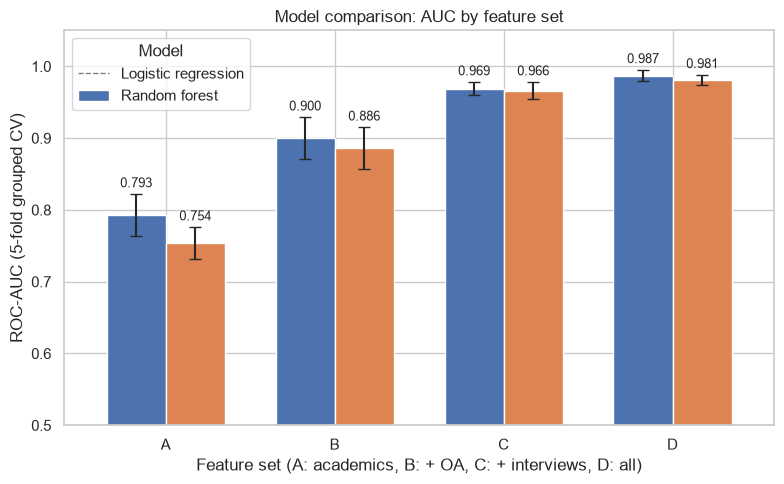

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
cfg.VISUALS_DIR.mkdir(exist_ok=True)

# Pivot: one row per feature set, one column per model
auc = results.pivot(index="features", columns="model", values="auc")
sd = results.pivot(index="features", columns="model", values="auc_sd")

ax = auc.plot(kind="bar", yerr=sd, capsize=4, figsize=(8, 5), width=0.7)

# Write the value on top of each bar
# Write values on top of each bar
for container in ax.containers:
    if isinstance(container, plt.matplotlib.container.BarContainer):
        ax.bar_label(
            container,
            fmt="%.3f",
            padding=3,
            fontsize=9
        )

ax.set_ylim(0.5, 1.05)                       # AUC of 0.5 = random guessing
ax.axhline(0.5, color="grey", ls="--", lw=1)
ax.set_xlabel("Feature set (A: academics, B: + OA, C: + interviews, D: all)")
ax.set_ylabel("ROC-AUC (5-fold grouped CV)")
ax.set_title("Model comparison: AUC by feature set")
ax.legend(title="Model", labels=["Logistic regression", "Random forest"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(cfg.VISUALS_DIR / "07_model_comparison_auc.png", dpi=150)
plt.show()